# Risk Contribution vs. Capital Weight

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Paired horizontal bars compare each asset's share of the capital with its share of the portfolio's total risk (volatility). In most portfolios the two differ sharply. A classic "60/40" portfolio gets most of its risk from equities, so the capital weights alone give a misleading picture of diversification.

## When to use

- Show where a portfolio's risk really comes from
- Explain risk-parity or risk-budgeting approaches
- Review a proposed allocation before it is implemented

## Avoid when

- More than about 12 holdings (aggregate to asset classes or sectors first)
- The audience has not been introduced to volatility as the risk measure

## Alternatives

- 100% stacked bars (capital vs. risk)
- Treemap sized by risk contribution

## Design tips

- Percent risk contributions sum to 100%: RC_i = w_i (Σw)_i / (w'Σw)
- Keep capital weights recessive (gray) and risk contributions in the primary color
- State the covariance estimation window and frequency

## Example

A simulated six-asset balanced portfolio with assumed annual volatilities and correlations. Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.ticker import PercentFormatter

### Data

In [2]:
assets = ["US equities", "Intl equities", "Gov. bonds", "Corp. bonds", "Gold", "Cash"]
weights = pd.Series([0.35, 0.15, 0.25, 0.15, 0.05, 0.05], index=assets)
vol = np.array([0.16, 0.18, 0.06, 0.07, 0.15, 0.005])          # annualised volatility
corr = np.array([[1.0, 0.85, -0.2, 0.3, 0.05, 0.0],
                 [0.85, 1.0, -0.15, 0.3, 0.1, 0.0],
                 [-0.2, -0.15, 1.0, 0.6, 0.25, 0.1],
                 [0.3, 0.3, 0.6, 1.0, 0.15, 0.1],
                 [0.05, 0.1, 0.25, 0.15, 1.0, 0.0],
                 [0.0, 0.0, 0.1, 0.1, 0.0, 1.0]])
cov = pd.DataFrame(np.outer(vol, vol) * corr, index=assets, columns=assets)
weights

US equities      0.35
Intl equities    0.15
Gov. bonds       0.25
Corp. bonds      0.15
Gold             0.05
Cash             0.05
dtype: float64

### Plot

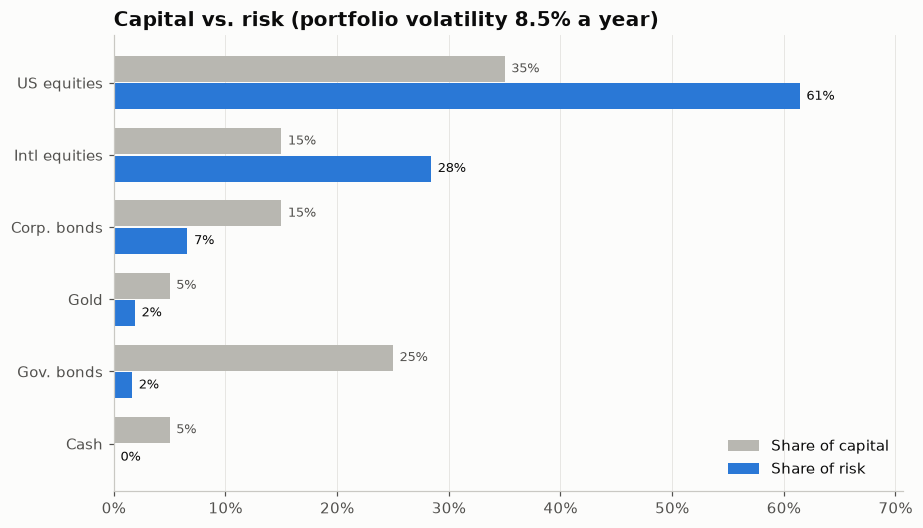

In [3]:
w = weights.values
port_var = w @ cov.values @ w
rc = pd.Series(w * (cov.values @ w) / port_var, index=weights.index)  # sums to 1
order = rc.sort_values().index
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8.5, 0.55 * len(order) + 1.6))
ax.barh(y + 0.19, weights[order], height=0.36, color=GRAY, label="Share of capital")
ax.barh(y - 0.19, rc[order], height=0.36, color=PALETTE[0], label="Share of risk")
for yi, a in zip(y, order):
    ax.text(weights[a] + 0.006, yi + 0.19, f"{weights[a]:.0%}", va="center", fontsize=8.5, color="#52514e")
    ax.text(max(rc[a], 0) + 0.006, yi - 0.19, f"{rc[a]:.0%}", va="center", fontsize=8.5, color="#0b0b0b")
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_yticks(y, order)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlim(min(0, rc.min() * 1.2), max(rc.max(), weights.max()) * 1.15)
ax.grid(axis="y", visible=False)
ax.set_title(f"Capital vs. risk (portfolio volatility {np.sqrt(port_var):.1%} a year)")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## How to read it

For each asset, the gray bar is its share of the money and the blue bar its share of total portfolio volatility. Equities hold about half the capital but generate most of the risk; bonds and cash hold capital but add little risk.

## Try it with real data

**Source:** plotly.express.data.stocks() — equal-weight portfolio of 6 tech stocks, covariance of weekly returns 2018–2019

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [4]:
import plotly.express as px
stocks = px.data.stocks().set_index("date")
cov = stocks.pct_change().dropna().cov() * 52           # annualised from weekly returns
weights = pd.Series(1 / len(cov), index=cov.index)
weights

GOOG    0.166667
AAPL    0.166667
AMZN    0.166667
FB      0.166667
NFLX    0.166667
MSFT    0.166667
dtype: float64

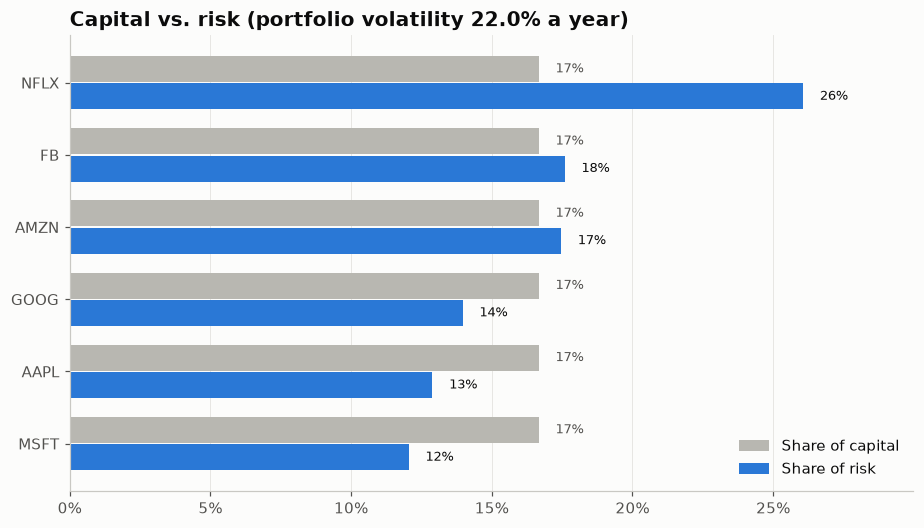

In [5]:
w = weights.values
port_var = w @ cov.values @ w
rc = pd.Series(w * (cov.values @ w) / port_var, index=weights.index)  # sums to 1
order = rc.sort_values().index
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8.5, 0.55 * len(order) + 1.6))
ax.barh(y + 0.19, weights[order], height=0.36, color=GRAY, label="Share of capital")
ax.barh(y - 0.19, rc[order], height=0.36, color=PALETTE[0], label="Share of risk")
for yi, a in zip(y, order):
    ax.text(weights[a] + 0.006, yi + 0.19, f"{weights[a]:.0%}", va="center", fontsize=8.5, color="#52514e")
    ax.text(max(rc[a], 0) + 0.006, yi - 0.19, f"{rc[a]:.0%}", va="center", fontsize=8.5, color="#0b0b0b")
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_yticks(y, order)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlim(min(0, rc.min() * 1.2), max(rc.max(), weights.max()) * 1.15)
ax.grid(axis="y", visible=False)
ax.set_title(f"Capital vs. risk (portfolio volatility {np.sqrt(port_var):.1%} a year)")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

---
Standalone script: [`risk_contribution.py`](risk_contribution.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)